# **Assignment 1**


**Anja Pijak**  
ap72051@student.uni-lj.si


In [136]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import seaborn as sns
from scipy import stats




#### Data preparation


In [4]:
df = pd.read_csv("datasets/podatki_PM_a1.csv")
df.fillna(df.mean(), inplace=True)

# datum dropped manually

df.head()

,Glob_sevanje_mean,Hitrost_vetra_mean,Sunki_vetra_max,Padavine_sum,Vlaga_mean,Temperatura_Krvavec_mean,Temperatura_lokacija_mean,PM10,PM_vceraj,sinD,cosD
0,0.125,0.6750,2.9,0.0,79.1750,-2.9875,3.2000,44.3,51.4,0.034899,0.999391
1,0.375,0.7375,2.6,0.0,93.5625,-4.5250,2.8750,49.0,44.3,0.052336,0.998630
2,0.875,0.8875,3.2,0.0,93.3000,2.9625,0.6875,61.3,49.0,0.069756,0.997564
3,0.750,1.0000,4.5,0.0,94.2625,2.9875,0.5875,38.9,61.3,0.087156,0.996195
4,0.250,0.5750,2.3,0.0,87.6500,-0.2500,3.1625,30.3,38.9,0.104528,0.994522


In [5]:
# attributes (all columns except for target col)
x = df.loc[:, df.columns != 'PM10']
print(x)

# target variable
y = df['PM10'] 
print(y)


      Glob_sevanje_mean  Hitrost_vetra_mean  Sunki_vetra_max  Padavine_sum  \
0                 0.125              0.6750              2.9           0.0   
1                 0.375              0.7375              2.6           0.0   
2                 0.875              0.8875              3.2           0.0   
3                 0.750              1.0000              4.5           0.0   
4                 0.250              0.5750              2.3           0.0   
...                 ...                 ...              ...           ...   
1208              0.375              0.6125              2.6           0.0   
1209              0.375              0.7125              3.9           0.0   
1210              1.750              1.7000              5.4           0.0   
1211              0.500              1.0375              4.9           0.0   
1212              0.375              0.6000              1.7           0.0   

      Vlaga_mean  Temperatura_Krvavec_mean  Temperatura_lokacij

#### Linear regression using SciKit-learn library

In [6]:
# 30-70 test-train
split = int(len(df) * 0.7) # to get index which is 70% of the dataset since rules of the assignment:
                                # "As the data is temporal do not perform random shuffle"

x_train, x_test = x[:split], x[split:]
y_train, y_test = y[:split], y[split:]


In [7]:
# with scikit learn
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print("done")

done


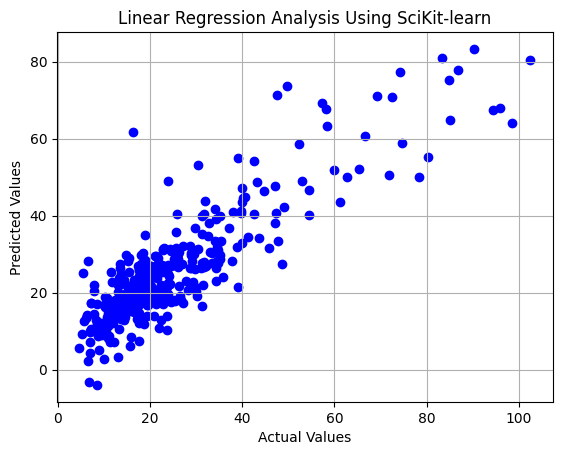

In [8]:
plt.scatter(y_test, y_pred, color='blue', label='Actual vs. Predicted')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression Analysis Using SciKit-learn")
plt.grid(True)
plt.show()


#### My implementation of linear regression

In [24]:
# Now, without library

# add column of all 1s
x['Ones'] = 1

# redo spliting because of the new column
x_train_mine, x_test_mine = x[:split], x[split:]
y_train_mine, y_test_mine = y[:split], y[split:]

In [25]:
# calculates beta from y_pred = x * beta formula
def calculateBeta(x, y):   
    xtx_inv = np.linalg.inv(np.dot(x.T, x))  # (X^T X)^(-1)
    xty = np.dot(x.T, y)  # X^T y
    beta = np.dot(xtx_inv, xty)  # (X^T X)^(-1) X^T y
    return beta


In [26]:
# Calculate beta using training data
beta = calculateBeta(x_train_mine, y_train_mine) 

# Predict using the training set and test set
y_train_pred_mine = np.dot(x_train_mine, beta)
y_test_pred_mine = np.dot(x_test_mine, beta)


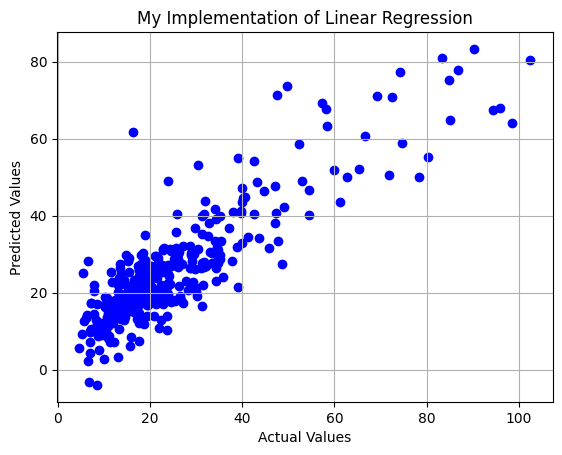

In [27]:
plt.scatter(y_test, y_test_pred_mine, color='blue', label='Actual vs. Predicted')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("My Implementation of Linear Regression")
plt.grid(True)
plt.show()


#### Comparing the two implementations

In [127]:
# Compare the two implementations

mae_scikit = mean_absolute_error(y_test, y_pred)
mse_scikit = mean_squared_error(y_test, y_pred)
r2_scikit = r2_score(y_test, y_pred)

print(f"MAE Scikit: {mae_scikit}")
print(f"MSE  Scikit: {mse_scikit}")
print(f"R2  Scikit: {r2_scikit}")


mae_mine = mean_absolute_error(y_test_mine, y_test_pred_mine)
mse_mine = mean_squared_error(y_test_mine, y_test_pred_mine)
r2_mine = r2_score(y_test_mine, y_test_pred_mine)

print(f"MAE with my implementation: {mae_mine}")
print(f"MSE with my implementation: {mse_mine}")
print(f"R2 with my implementation: {r2_mine}")


MAE Scikit: 6.041491247227988
MSE  Scikit: 69.9312296540761
R2  Scikit: 0.7676374067779344
MAE with my implementation: 6.041491247228126
MSE with my implementation: 69.93122965407703
R2 with my implementation: 0.7676374067779312


#### Diagnosing my implementation with diagnostic plots

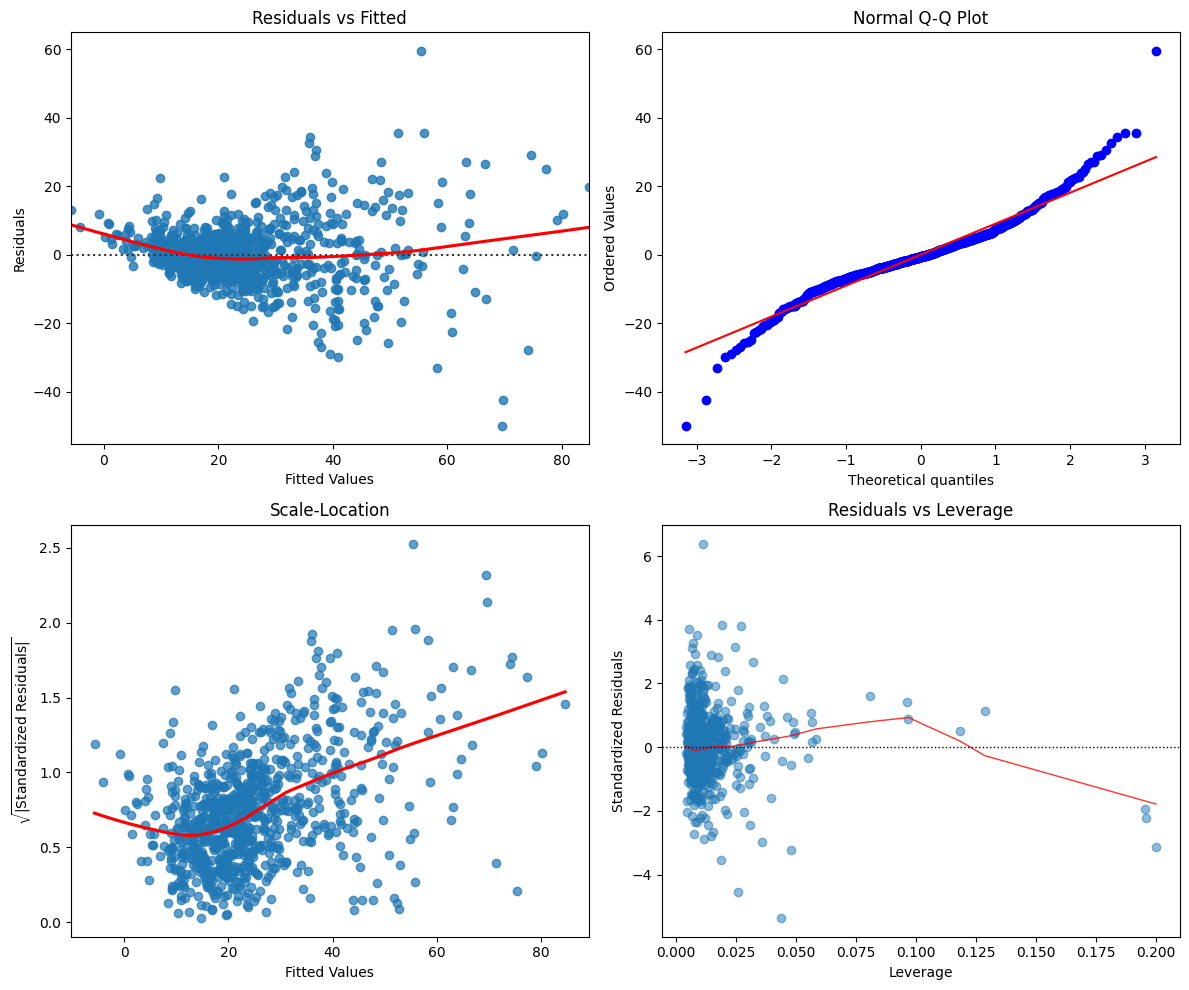

In [138]:
# Calculate residuals and standardized residuals
residuals = y_train_mine - y_train_pred_mine
standardized_residuals = residuals / np.std(residuals)

# Calculate leverage values for Residuals vs Leverage plot:
# hat matrix: H = X(X^TX)^-1X^T, and leverage is the diagonal of this matrix
H = np.dot(x_train_mine, np.linalg.inv(np.dot(x_train_mine.T, x_train_mine))).dot(x_train_mine.T)
leverage = np.diag(H)

# 2x2 grid
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Residual plot
sns.residplot(x=y_train_pred_mine, y=residuals, lowess=True, line_kws={'color': 'red'}, ax=axs[0, 0])
axs[0, 0].set_xlabel("Fitted Values")
axs[0, 0].set_ylabel("Residuals")
axs[0, 0].set_title("Residuals vs Fitted")

# Q-Q plot 
stats.probplot(residuals, dist="norm", plot=axs[0, 1])
axs[0, 1].set_title("Normal Q-Q Plot")

# Scale-Location plot
sqrt_abs_standardized_residuals = np.sqrt(np.abs(standardized_residuals)) 
axs[1, 0].scatter(y_train_pred_mine, sqrt_abs_standardized_residuals, alpha=0.7)
sns.regplot(x=y_train_pred_mine, y=sqrt_abs_standardized_residuals, lowess=True, line_kws={'color': 'red'}, scatter=False, ax=axs[1, 0])
axs[1, 0].set_xlabel("Fitted Values")
axs[1, 0].set_ylabel(r'$\sqrt{|\mathrm{Standardized\ Residuals}|}$')
axs[1, 0].set_title("Scale-Location")

# Residuals vs Leverage plot
axs[1, 1].scatter(leverage, standardized_residuals, alpha=0.5)
sns.regplot(x=leverage, y=standardized_residuals, scatter=False, ci=False, lowess=True, line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8}, ax=axs[1, 1])
axs[1, 1].axhline(0, ls='dotted', color='black', lw=1)
axs[1, 1].set_title('Residuals vs Leverage')
axs[1, 1].set_xlabel('Leverage')
axs[1, 1].set_ylabel('Standardized Residuals')


plt.tight_layout()
plt.show()


#### Trying to make improvements to the model

First, trying with correlation matrix. 
That should help me better see the relationships between the attributes.

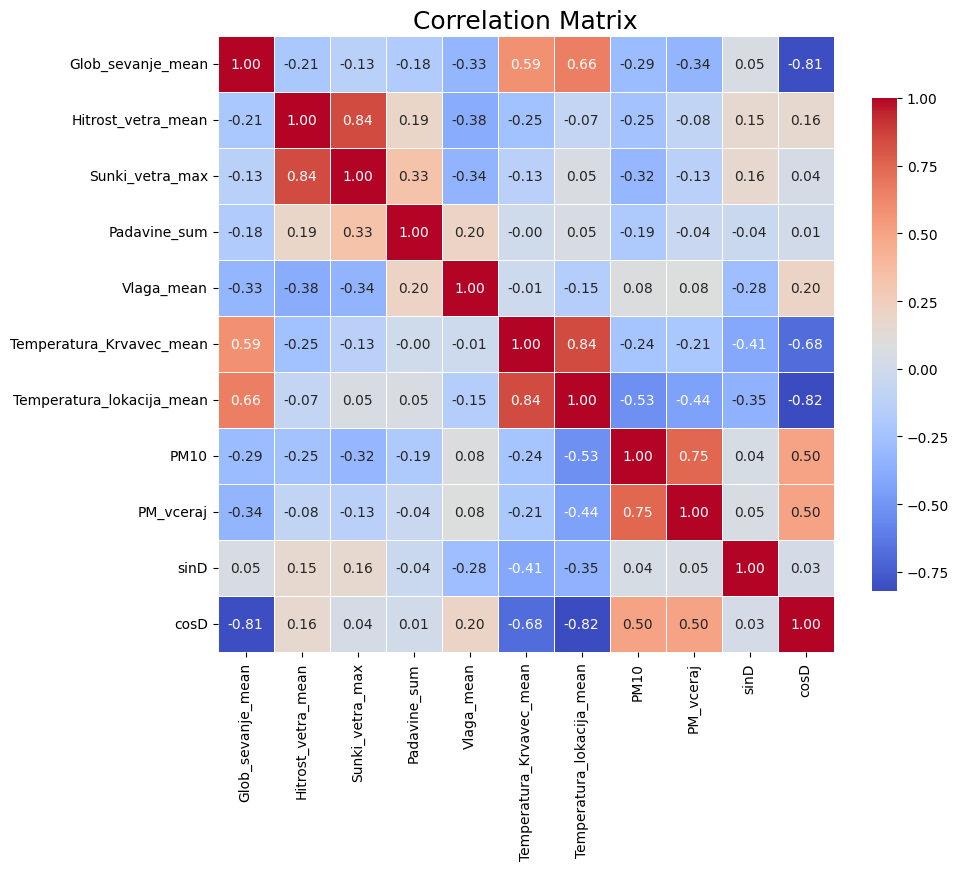

In [89]:
correlation_matrix = df.corr()

plt.figure(figsize=(10, 8))

# Creating a heatmap
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8}, linewidths=.5)           
plt.title("Correlation Matrix", fontsize=18)
plt.show()

From correlation matrix we see that highest correlations between target PM10 are with following columns:
- cosD
- PM_vceraj
- Temperatura_lokacija_mean 
- Sunki_vetra_max

So let's try using only those columns as attributes:

In [142]:
x_corr = df.loc[:,['cosD','PM_vceraj', 'Temperatura_lokacija_mean', 'Sunki_vetra_max']]
x_corr['Ones'] = 1

x_train_corr, x_test_corr = x_corr[:split], x_corr[split:]
y_train_corr, y_test_corr = y[:split], y[split:]


beta_corr = calculateBeta(x_train_corr, y_train_corr)

y_train_pred_corr = np.dot(x_train_corr, beta_corr)
y_test_pred_corr = np.dot(x_test_corr, beta_corr)

In the following results we can see that this doesn't help our model, as it gives worse results for each metric.

Even if I add more attributes ('Sunki_vetra_max', 'Glob_sevanje_mean', 'Hitrost_vetra_mean', 'Padavine_sum'),
based on their correlation scores, the results are never better then the original for all 3 metrics.

In [166]:
mae_corr = mean_absolute_error(y_test_corr, y_test_pred_corr)
mse_corr = mean_squared_error(y_test_corr, y_test_pred_corr)
r2 = r2_score(y_test_corr, y_test_pred_corr)

print(f"MAE original: {mae_mine}")
print(f"MSE original: {mse_mine}")
print(f"R2 original: {r2_mine}",  end="\n\n")

print(f"MAE after taking into consideration correlations: {mae_corr}")
print(f"MSE after taking into consideration correlations: {mse_corr}")
print(f"R2 after taking into consideration correlations: {r2}")



MAE original: 6.041491247228126
MSE original: 69.93122965407703
R2 original: 0.7676374067779312

MAE after taking into consideration correlations: 6.4880186226836525
MSE after taking into consideration correlations: 79.15952626472041
R2 after taking into consideration correlations: 0.7369742689770001


I will also try ridge regression which has a regularization term in the cost function.

The formula for Ridge regression coefficients is y_pred = X*beta where beta = (X^T X + λI)^(-1) X^T y so I will just adjust beta formula from my initial implementation

In [185]:
def calculateRidgeBeta(x, y, lambda_):
    n,m = x.shape
    I = np.eye(m)  # Create an identity matrix of size (m, m)
   
    xtx_inv = np.linalg.inv(np.dot(x.T, x) + lambda_ * I)  # (X^T X + λI)^(-1)
    xty = np.dot(x.T, y)  # X^T y
    return np.dot(xtx_inv, xty)


We see in the following validation results that this produces better results for all three metrics. The improvements are small, but they do exist.

In [187]:
lambda_ = 1.0 

# Calculate Ridge regression coefficients
beta_ridge = calculateRidgeBeta(x_train_mine, y_train_mine, lambda_)

# Make predictions
y_train_pred_ridge = np.dot(x_train_mine,beta_ridge)
y_test_pred_ridge = np.dot(x_test_mine,beta_ridge)

# Calculate evaluation metrics
mae_ridge = mean_absolute_error(y_test_mine, y_test_pred_ridge)
mse_ridge = mean_squared_error(y_test_mine, y_test_pred_ridge)
r2_ridge = r2_score(y_test_mine, y_test_pred_ridge)

print(f"MAE original: {mae_mine}")
print(f"MSE original: {mse_mine}")
print(f"R2 original: {r2_mine}", end="\n\n")

# Print the evaluation metrics
print(f"MAE after Ridge regression: {mae_ridge}")
print(f"MSE after Ridge regression: {mse_ridge}")
print(f"R2 after Ridge regression: {r2_ridge}")

MAE original: 6.041491247228126
MSE original: 69.93122965407703
R2 original: 0.7676374067779312

MAE after Ridge regression: 5.993425164997525
MSE after Ridge regression: 69.42930265668984
R2 after Ridge regression: 0.7693051746592909
